# 高德地图 API 的 POI 下载、投影转换与可视化

**任务**：调用高德地图 Web 服务 API 下载苏州市旅游景点 POI → 坐标纠偏并转换到合适的投影坐标系 → 绘制景点分布地图与统计图。

**技术路线**：行政区划边界接口 → 文本搜索接口（按"区县 × 三级类型"拆分下载，突破单次查询 225 条上限）→ GCJ-02 坐标纠偏为 WGS84 → 投影到 UTM 51N（EPSG:32651）→ matplotlib 制图 → 导出 CSV / GeoJSON / GeoPackage。

In [ ]:
import math
import os
import time
from pathlib import Path

import geopandas as gpd 
import matplotlib.pyplot as plt
import pandas as pd
import requests
from shapely.geometry import Polygon

#读取密钥
def _load_key():

    import re
    candidates = [Path.cwd() / "amap_poi_search.py"]
    candidates += [p / "amap_poi_search.py" for p in Path.cwd().glob("*/")]
    candidates += [p / "amap_poi_search.py" for p in Path.cwd().parents]
    for f in candidates:
        if f.is_file():
            m = re.search(r'KEY\s*=\s*"([0-9a-fA-F]+)"', f.read_text(encoding="utf-8"))
            if m:
                return m.group(1)
    raise FileNotFoundError("未找到 amap_poi_search.py，请确认密钥文件与本 notebook 在同一仓库")

KEY = _load_key()
print("高德密钥已加载（前缀", KEY[:4], "…）")

# 中文字体与负号显示
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

OUT_DIR = "data/amap_poi"      # 输出目录（data/ 已在 .gitignore 中）
os.makedirs(OUT_DIR, exist_ok=True)

高德密钥已加载（前缀 aa67 …）


## 1. 下载苏州市及各区县行政边界

行政区划查询接口 `v3/config/district`。边界坐标串的格式：`|` 分隔多个环（飞地/岛屿）、`;` 分隔点、`,` 分隔经纬度。

注意：查询市级时返回的子区县**不带边界**，需要按区县名逐个再查一次。

In [2]:
DISTRICT_URL = "https://restapi.amap.com/v3/config/district"

def get_district(keywords):
    """查询行政区信息，返回含边界 polyline 的字典。"""
    data = requests.get(DISTRICT_URL, params=dict(key=KEY, keywords=keywords,
                                                  extensions="all"), timeout=15).json()
    if data["status"] != "1":
        raise RuntimeError(f"请求失败 [{data['infocode']}]：{data['info']}")
    return data["districts"][0]

city_bd = get_district("苏州市")                                        # 市界
districts_bd = [get_district(d["name"]) for d in city_bd["districts"]]  # 各区县逐个查
print("市界：", city_bd["name"])
print("区县：", [d["name"] for d in districts_bd])

市界： 苏州市
区县： ['虎丘区', '姑苏区', '常熟市', '昆山市', '张家港市', '相城区', '太仓市', '吴中区', '吴江区']


## 2. 下载 POI 数据（文本搜索接口，按"区县 × 三级类型"拆分）

- 接口：`https://restapi.amap.com/v3/place/text`，每页最多 25 条，需翻页取全
- 实测限制：**单次查询最多返回 225 条**（翻到第 10 页后返回空），直接查"风景名胜"大类时每个区县都会触顶，各区县数量无法比较
- 因此把大类 110000 拆成 15 个三级类型（公园、城市广场、观景点……），按 **区县 × 类型** 分别查询：每个子查询的数量都在上限之内，求和即得各区县真实总数（个别触顶的会标注 ⚠）

In [3]:
TEXT_URL = "https://restapi.amap.com/v3/place/text"

# 风景名胜大类(110000)下的三级类型及名称（用"类型代码"查询可突破关键字匹配的遗漏）
TYPE_CODES = {
    "公园": "110101", "动物园": "110102", "植物园": "110103", "水族馆": "110104",
    "城市广场": "110105", "公园内部设施": "110106",
    "世界遗产": "110201", "国家级景点": "110202", "省级景点": "110203",
    "纪念馆": "110204", "寺庙道观": "110205", "教堂": "110206",
    "回教寺": "110207", "海滩": "110208", "观景点": "110209",
}

def search_all_poi(district_names):
    """按 区县 × 三级类型 拆分下载苏州市全部风景名胜 POI。"""
    frames = []
    for name in district_names:
        district_pois = []
        for label, tcode in TYPE_CODES.items():
            pois, page = [], 1
            while True:
                params = dict(key=KEY, types=tcode, city=name, citylimit="true",
                              offset=25, page=page, extensions="all")
                data = requests.get(TEXT_URL, params=params, timeout=15).json()
                if data["status"] != "1":
                    raise RuntimeError(f"请求失败 [{data['infocode']}]：{data['info']}")
                pois += data["pois"]
                if not data["pois"]:
                    break
                page += 1
                time.sleep(0.2)   # 限速（免费配额 QPS 约 3 次/秒）
            if len(pois) == 225:
                print(f"  {name}·{label}: {len(pois)} 条 ⚠ 达到接口上限，实际可能更多")
            district_pois += pois
            time.sleep(0.2)
        print(f"{name}: 共 {len(district_pois)} 条")
        frames.append(pd.DataFrame(district_pois))

    df = pd.concat(frames, ignore_index=True).drop_duplicates(subset="id")
    # 电话字段是列表，转成字符串便于导出
    df["tel"] = df["tel"].apply(lambda t: ";".join(t) if isinstance(t, list) else t)
    print(f"下载完成：去重后共 {len(df)} 条")
    return df

poi_df = search_all_poi([d["name"] for d in districts_bd])
poi_df[["name", "type", "adname", "address", "location"]].head()

虎丘区: 共 321 条


  姑苏区·观景点: 225 条 ⚠ 达到接口上限，实际可能更多
姑苏区: 共 568 条


常熟市: 共 436 条


昆山市: 共 603 条


张家港市: 共 254 条


...

太仓市: 共 187 条


  吴中区·寺庙道观: 225 条 ⚠ 达到接口上限，实际可能更多


吴中区: 共 765 条


吴江区: 共 448 条
下载完成：去重后共 3845 条


,name,type,adname,address,location
0,新区公园,风景名胜;公园广场;公园,虎丘区,何山路279号,"120.537829,31.302275"
1,白鹭园,风景名胜;公园广场;公园,虎丘区,苏州工业园区翠薇街101号(近独墅湖图书馆),"120.720819,31.270827"
2,华通公园,风景名胜;公园广场;公园,虎丘区,通安镇(好客来宾馆东),"120.468584,31.376655"
3,杵山生态公园,风景名胜;公园广场;公园,虎丘区,北太湖大道1200号,"120.325729,31.331293"
4,智慧谷,风景名胜;公园广场;公园,虎丘区,苏州科技城玉屏路智慧谷,"120.427388,31.312745"


## 3.1 坐标系转换：GCJ-02 → WGS84 → UTM 51N

**为什么要纠偏？** 高德（以及国内多数地图商）返回的是 GCJ-02「火星坐标」，与真实 WGS84 坐标存在约 300~500 m 的系统性偏移。若不纠偏，直接与 OSM / 遥感影像等 WGS84 数据叠加会出现明显错位。

**为什么选 UTM 51N？**
- 苏州主城区经度约 120.6°E，落在 UTM 第 51 带（120°E~126°E），对应 EPSG:32651；
- 投影后单位为米，可直接量算距离、面积；
- 与课程 OSM 数据的投影（`data/suzhou_gusu/*_utm.gpkg`，EPSG:32651）一致，可无缝叠加。

（中国测绘标准投影 CGCS2000 高斯-克吕格 3° 分带 EPSG:4528 也是等价选择，这里沿用课程数据的 UTM。）

In [4]:
def gcj02_to_wgs84(lng, lat):
    """GCJ-02 → WGS84 标准纠偏算法（国测局加密算法的逆变换）。"""
    x, y = lng - 105.0, lat - 35.0
    A, EE = 6378245.0, 0.00669342162296594323
    dlat = (-100 + 2 * x + 3 * y + 0.2 * y * y + 0.1 * x * y + 0.2 * math.sqrt(abs(x))
            + (20 * math.sin(6 * x * math.pi) + 20 * math.sin(2 * x * math.pi)) * 2 / 3
            + (20 * math.sin(y * math.pi) + 40 * math.sin(y / 3 * math.pi)) * 2 / 3
            + (160 * math.sin(y / 12 * math.pi) + 320 * math.sin(y * math.pi / 30)) * 2 / 3)
    dlng = (300 + x + 2 * y + 0.1 * x * x + 0.1 * x * y + 0.1 * math.sqrt(abs(x))
            + (20 * math.sin(6 * x * math.pi) + 20 * math.sin(2 * x * math.pi)) * 2 / 3
            + (20 * math.sin(x * math.pi) + 40 * math.sin(x / 3 * math.pi)) * 2 / 3
            + (150 * math.sin(x / 12 * math.pi) + 300 * math.sin(x / 30 * math.pi)) * 2 / 3)
    radlat = math.radians(lat)
    magic = 1 - EE * math.sin(radlat) ** 2
    sqrtmagic = math.sqrt(magic)
    dlat = (dlat * 180.0) / ((A * (1 - EE)) / (magic * sqrtmagic) * math.pi)
    dlng = (dlng * 180.0) / (A / sqrtmagic * math.cos(radlat) * math.pi)
    return lng - dlng, lat - dlat

In [5]:
def polyline_to_polygons(polyline):
    """高德边界坐标串 → 若干 shapely 多边形（| 分环，; 分点，, 分经纬度）。"""
    polygons = []
    for ring in polyline.split("|"):
        pts = [tuple(map(float, p.split(","))) for p in ring.split(";") if p]
        if len(pts) >= 3:
            wgs = [gcj02_to_wgs84(lon, lat) for lon, lat in pts]
            polygons.append(Polygon(wgs))
    return polygons

# ① POI 点：纠偏 → 建立 GeoDataFrame → 投影到 UTM 51N
coords = poi_df["location"].str.split(",", expand=True).astype(float)
poi_df["wgs_lon"], poi_df["wgs_lat"] = zip(*[gcj02_to_wgs84(l, a) for l, a in zip(coords[0], coords[1])])

poi_gdf = gpd.GeoDataFrame(poi_df,
                           geometry=gpd.points_from_xy(poi_df["wgs_lon"], poi_df["wgs_lat"]),
                           crs="EPSG:4326")
poi_utm = poi_gdf.to_crs("EPSG:32651")

# ② 行政边界：纠偏 + 投影（每个环一条记录）
rows = []
for d in [city_bd] + districts_bd:
    rows += [{"name": d["name"], "adcode": d["adcode"], "geometry": p}
             for p in polyline_to_polygons(d["polyline"])]
boundary = gpd.GeoDataFrame(rows, crs="EPSG:4326").to_crs("EPSG:32651")

print("POI 数量：", len(poi_utm))
print("投影后坐标范围（米）：")
print("  X:", poi_utm.total_bounds[:2].round(0))
print("  Y:", poi_utm.total_bounds[2:].round(0))
print("各区县边界环数：")
print(boundary.groupby("name").size())

POI 数量： 3845
投影后坐标范围（米）：
  X: [ 233739. 3408557.]
  Y: [ 338183. 3545697.]
各区县边界环数：
name
吴中区     1
吴江区     1
太仓市     1
姑苏区     1
常熟市     1
张家港市    1
昆山市     2
相城区     1
苏州市     2
虎丘区     2
dtype: int64


## 3.2 验证纠偏效果

课程 OSM 道路数据（真实 WGS84 基准）覆盖姑苏区一带，纠偏正确的话，**绝大多数姑苏区景点应落在道路数据范围内**；若比例接近 0%，说明坐标系转换出了错。

In [6]:
roads_check = gpd.read_file("data/suzhou_gusu/roads_utm.gpkg")   # 真实 WGS84 基准（课程数据）

minx, miny, maxx, maxy = roads_check.total_bounds
gusu_poi = poi_utm[poi_utm["adname"] == "姑苏区"]
inside = gusu_poi.cx[minx:maxx, miny:maxy]
ratio = len(inside) / len(gusu_poi)
print(f"姑苏区景点落在 OSM 道路范围内的比例: {len(inside)} / {len(gusu_poi)} = {ratio:.0%}")
print("（纠偏正确时比例接近 100%；接近 0% 则说明坐标系转换有问题）")

姑苏区景点落在 OSM 道路范围内的比例: 566 / 567 = 100%
（纠偏正确时比例接近 100%；接近 0% 则说明坐标系转换有问题）


## 4. 绘制景点分布地图

以区县边界为底图，景点按所在区县着色；坐标轴是 UTM 投影下的米制坐标（东向 X / 北向 Y）。

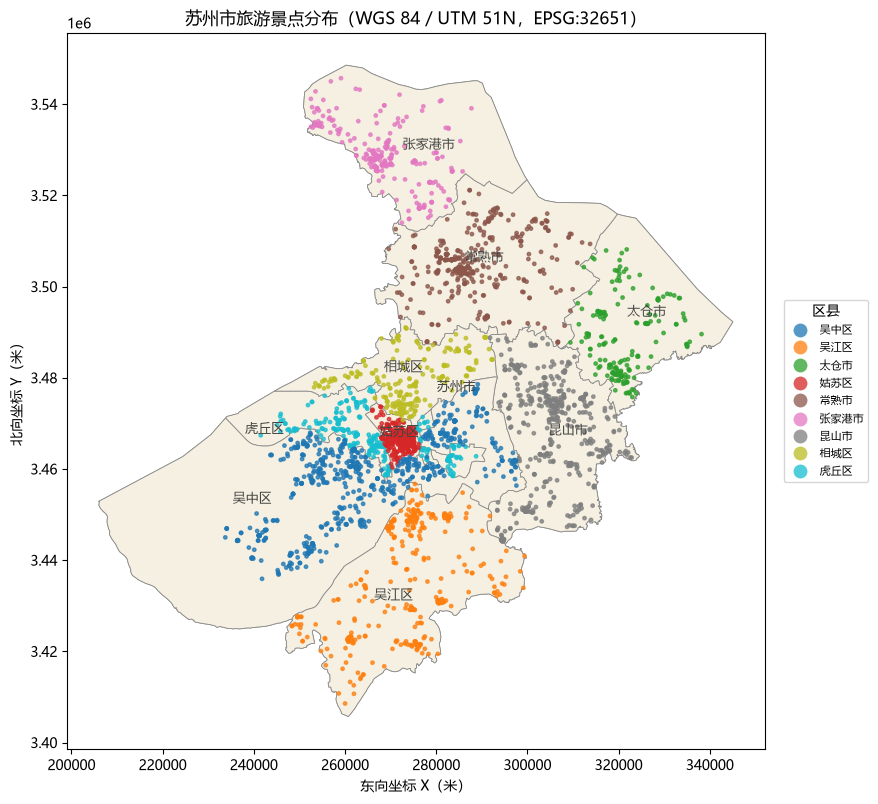

In [7]:
fig, ax = plt.subplots(figsize=(9, 10))

# 底图：区县边界 + 区县名
boundary.plot(ax=ax, facecolor="#f5f0e1", edgecolor="#8a8a8a", linewidth=0.6)
for name, row in boundary.dissolve("name").iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(name, (pt.x, pt.y), ha="center", fontsize=9, color="#444444")

# 景点：按所在区县着色
poi_utm.plot(ax=ax, column="adname", categorical=True, cmap="tab10",
             markersize=6, alpha=0.75, legend=True,
             legend_kwds={"title": "区县", "loc": "center left",
                          "bbox_to_anchor": (1.02, 0.5), "fontsize": 8})

ax.set_title("苏州市旅游景点分布（WGS 84 / UTM 51N，EPSG:32651）")
ax.set_xlabel("东向坐标 X（米）")
ax.set_ylabel("北向坐标 Y（米）")
ax.set_aspect("equal")
fig.savefig(os.path.join(OUT_DIR, "苏州旅游景点分布图.png"), dpi=200, bbox_inches="tight")
plt.show()

## 5. 统计图

左图：各区县景点数量对比（按区县拆分下载后各区县数量真实可比）；右图：景点类型构成。高德的 `type` 字段用 `;` 分三级：大类;中类;小类，如 `风景名胜;公园广场;公园`。

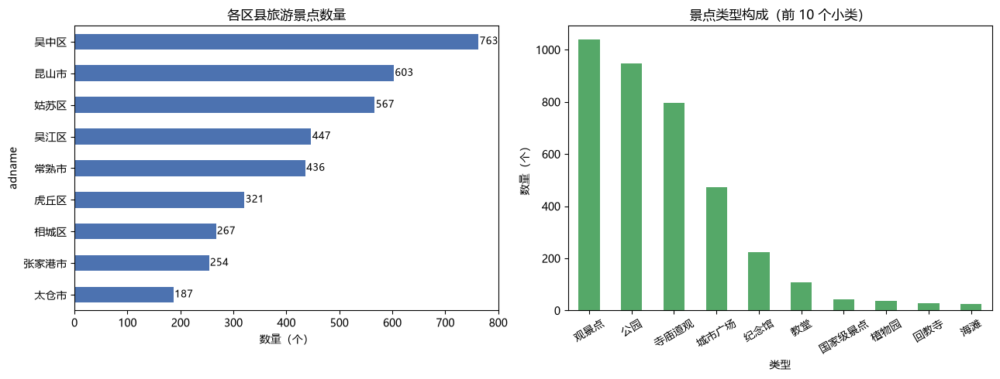

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 左：各区县景点数量（横向条形，按数量排序）
counts = poi_utm["adname"].value_counts().sort_values()
counts.plot.barh(ax=axes[0], color="#4C72B0")
for i, v in enumerate(counts):
    axes[0].text(v + 2, i, str(v), va="center", fontsize=9)
axes[0].set_title("各区县旅游景点数量")
axes[0].set_xlabel("数量（个）")

# 右：景点类型（小类）构成，取前 10
poi_utm["小类"] = poi_utm["type"].str.split(";").str[2].fillna("其他")
type_counts = poi_utm["小类"].value_counts().head(10)
type_counts.plot.bar(ax=axes[1], color="#55A868")
axes[1].set_title("景点类型构成（前 10 个小类）")
axes[1].set_xlabel("类型")
axes[1].set_ylabel("数量（个）")
axes[1].tick_params(axis="x", rotation=30)

fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "苏州旅游景点统计图.png"), dpi=200, bbox_inches="tight")
plt.show()

## 6. 数据导出

- **CSV**：WGS84 经纬度，便于 Excel 查看（`utf-8-sig` 编码，Excel 打开不乱码）
- **GeoJSON**：经纬度，通用交换格式
- **GeoPackage**：UTM 51N 投影坐标，可直接拖进 QGIS 与课程数据叠加、量算

In [9]:
cols = ["name", "adname", "type", "address", "tel", "wgs_lon", "wgs_lat"]
poi_df[cols].to_csv(os.path.join(OUT_DIR, "苏州旅游景点.csv"), index=False, encoding="utf-8-sig")

gcols = ["name", "adname", "type", "address", "geometry"]
poi_gdf[gcols].to_file(os.path.join(OUT_DIR, "苏州旅游景点_wgs84.geojson"), driver="GeoJSON")
poi_utm[gcols].to_file(os.path.join(OUT_DIR, "苏州旅游景点_utm51n.gpkg"), driver="GPKG")
boundary[["name", "adcode", "geometry"]].to_file(os.path.join(OUT_DIR, "苏州区县边界_utm51n.gpkg"), driver="GPKG")

print("导出完成：")
for f in os.listdir(OUT_DIR):
    print(" ", f)

导出完成：
  苏州区县边界_utm51n.gpkg
  苏州旅游景点.csv
  苏州旅游景点_utm51n.gpkg
  苏州旅游景点_wgs84.geojson
  苏州旅游景点分布图.png
  苏州旅游景点统计图.png
  苏州景点交互地图.html


## 7. 交互地图：景点与 OSM 道路叠加
- **交互地图用经纬度（EPSG:4326）**：Web 制图的标准做法；UTM 投影适合量算与静态制图，两者用途不同，用 `to_crs` 可随时互转
- 底图 OpenStreetMap 是 WGS84 基准，与我们纠偏后的数据一致、能正确叠加（高德的在线瓦片是 GCJ-02 坐标，不能直接当底图，否则又会出现几百米错位）
- 多层叠加用 `m=m` 参数：先把边界、道路、景点逐层 `explore` 到同一张地图上，右上角图层控件可分别开关；地图同时保存为独立 HTML，可直接用浏览器打开

In [10]:
import folium

# 交互地图使用经纬度（EPSG:4326），把 UTM 投影数据转回去
poi_wgs = poi_utm.to_crs("EPSG:4326")
roads_wgs = gpd.read_file("data/suzhou_gusu/roads_utm.gpkg").to_crs("EPSG:4326")
boundary_wgs = boundary.to_crs("EPSG:4326")

# 以姑苏区景点中心为初始视野
gusu = poi_wgs[poi_wgs["adname"] == "姑苏区"]
center = gusu.geometry.union_all().centroid
m = folium.Map(location=[center.y, center.x], zoom_start=13)

# explore(m=m) 表示叠加到已有的地图上，逐层添加
m = boundary_wgs.explore(m=m, name="区县边界",
                         style_kwds={"color": "#666666", "weight": 1.5, "fillOpacity": 0})
m = roads_wgs.explore(m=m, name="OSM 道路（姑苏区一带）",
                      style_kwds={"color": "#b0b0b0", "weight": 1, "opacity": 0.8})
m = poi_wgs.explore(m=m, name="旅游景点",
                    column="adname", cmap="tab10", legend=True,
                    legend_kwds={"caption": "区县", "loc": "bottomright"},
                    marker_kwds={"radius": 4, "fillOpacity": 0.6},
                    tooltip=["name"],
                    popup=["name", "adname", "address"])

folium.LayerControl().add_to(m)   # 右上角图层开关
m.save(os.path.join(OUT_DIR, "苏州景点交互地图.html"))
m   # 在 notebook 中直接显示交互地图

## 小结

1. 高德 API 返回 GCJ-02 坐标，与 WGS84 存在约 300~500 m 的系统性偏移，叠加其他数据前**必须纠偏**；
2. 苏州（约 120.6°E）适合 UTM 51N 投影（EPSG:32651），与课程 OSM 数据投影一致；
3. 高德文本搜索单次查询最多返回 225 条，采用"区县 × 三级类型"拆分下载才能拿到各区县真实数量（个别子查询触顶的已在输出中标注 ⚠）；
4. 全套结果已导出到 `data/amap_poi/`：CSV、GeoJSON（经纬度）、GeoPackage（投影坐标）、folium 交互地图（HTML）。